# RCA Activity: Women's Clothing Recommendation Prediction using Logistic Regression



## Objective
Predict whether a customer recommends a women's clothing product using only three simple input features.

Recommended IND = 0: Not recommended

Recommended IND = 1: Recommended


**Kaggle source:** https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews



## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload and load the Kaggle dataset

In [2]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
df.columns = df.columns.str.strip()
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 3. Inspect the dataset

In [3]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()

First five rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Last five rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses
23485,23485,1104,52,Please make more like this one!,This dress in a lovely platinum is feminine an...,5,1,22,General Petite,Dresses,Dresses


Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object


In [4]:
print("Statistical summary:")
display(df.describe())

Statistical summary:


,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,11742.500000,918.118709,43.198544,4.196032,0.822362,2.535936
std,6779.968547,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000
25%,5871.250000,861.000000,34.000000,4.000000,1.000000,0.000000
50%,11742.500000,936.000000,41.000000,5.000000,1.000000,1.000000
75%,17613.750000,1078.000000,52.000000,5.000000,1.000000,3.000000
max,23485.000000,1205.000000,99.000000,5.000000,1.000000,122.000000


## 4. Select input features and target


- Age
- Rating
- Positive Feedback Count

The target column is Recommended IND.



In [5]:
features = ["Age", "Rating", "Positive Feedback Count"]
target = "Recommended IND"

required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns not found in uploaded CSV: {missing_columns}")

data = df[required_columns].copy()

for col in required_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=[target])
data[target] = data[target].astype(int)

X = data[features]
y = data[target]

print("Selected dataset shape:", data.shape)
print("Input features:", features)
print("Target distribution:")
display(y.value_counts().sort_index())

Selected dataset shape: (23486, 4)
Input features: ['Age', 'Rating', 'Positive Feedback Count']
Target distribution:


,count
Recommended IND,
0,4172
1,19314


## 5. Check missing values and duplicates

In [6]:
missing_summary = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (data.isnull().mean() * 100).round(2)
})
display(missing_summary)

print("Duplicate rows:", data.duplicated().sum())

,Missing Count,Missing Percentage
Age,0,0.0
Rating,0,0.0
Positive Feedback Count,0,0.0
Recommended IND,0,0.0


Duplicate rows: 19793


## 6. Exploratory Data Analysis (EDA)

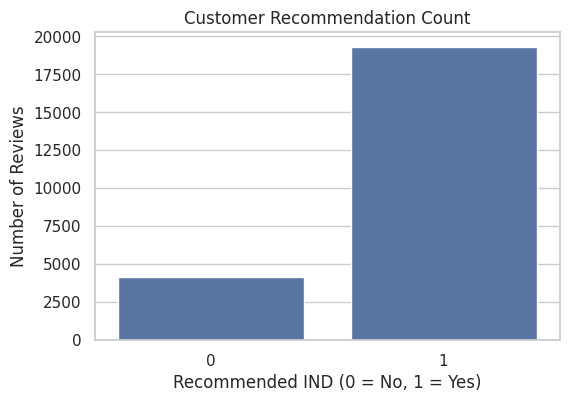

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x=target)
plt.title("Customer Recommendation Count")
plt.xlabel("Recommended IND (0 = No, 1 = Yes)")
plt.ylabel("Number of Reviews")
plt.show()

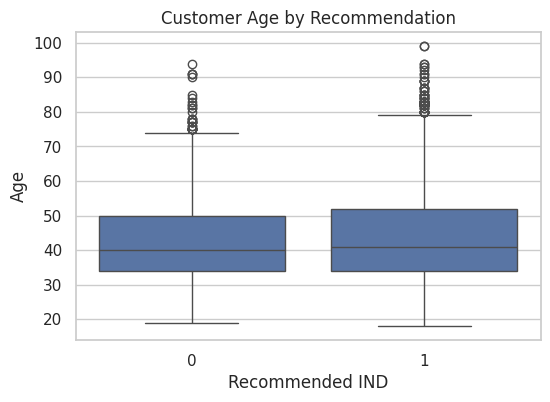

In [8]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x=target, y="Age")
plt.title("Customer Age by Recommendation")
plt.xlabel("Recommended IND")
plt.ylabel("Age")
plt.show()

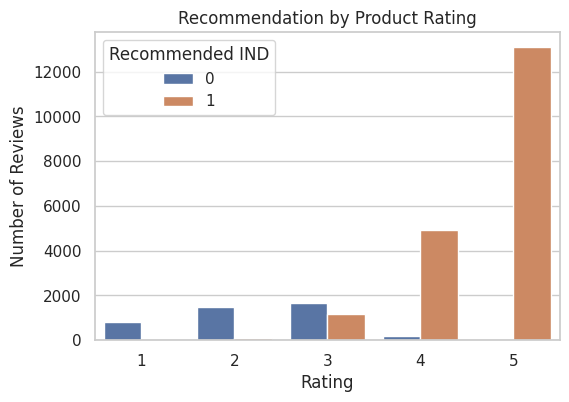

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Rating", hue=target)
plt.title("Recommendation by Product Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

## 7. Split the data into training and testing sets

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 18788
Testing records: 4698


## 8. Build and train the Logistic Regression model

In [11]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 9. Make predictions

In [12]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
display(prediction_results.head(10))

,Actual,Predicted
0,0,0
1,1,1
2,1,1
3,1,1
4,1,0
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


## 10. Evaluate the model

In [13]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_probability):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  0.9338
Precision: 0.9756
Recall:    0.9430
F1-score:  0.9591
ROC-AUC:   0.9715

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.89      0.83       835
           1       0.98      0.94      0.96      3863

    accuracy                           0.93      4698
   macro avg       0.87      0.92      0.89      4698
weighted avg       0.94      0.93      0.94      4698



## 11. Confusion matrix

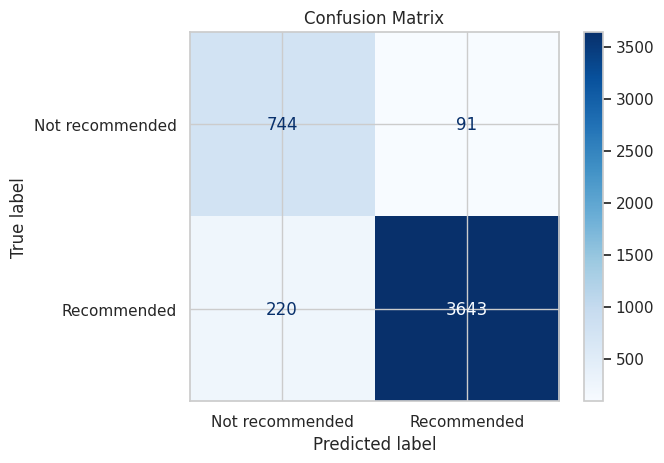

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not recommended", "Recommended"],
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

## 12. ROC curve

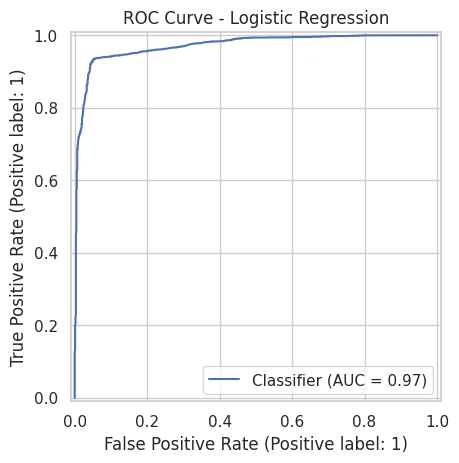

In [15]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Logistic Regression")
plt.show()

## 13. Predict for a new customer review

In [16]:
new_review = pd.DataFrame([{
    "Age": 28,
    "Rating": 5,
    "Positive Feedback Count": 2
}])

predicted_class = model.predict(new_review)[0]
recommendation_probability = model.predict_proba(new_review)[0][1]

print("Predicted class:", predicted_class)
print(f"Estimated recommendation probability: {recommendation_probability:.2%}")

if predicted_class == 1:
    print("Prediction: Customer is predicted to recommend the product.")
else:
    print("Prediction: Customer is predicted not to recommend the product.")

Predicted class: 1
Estimated recommendation probability: 99.78%
Prediction: Customer is predicted to recommend the product.


In [17]:

data.to_csv("Womens_Clothing_Cleaned.csv", index=False)


## 14. Conclusion

In this activity, a Logistic Regression model was developed to predict whether a customer recommends a women's clothing product. Only three input features were used: age, rating and positive feedback count. The data was inspected, missing values were handled, and numerical features were scaled. The dataset was divided into training and testing sets, and the model was evaluated using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.

**Limitation:** Rating is recorded as part of a review, so this model estimates recommendation after a customer has submitted a rating. It does not predict a recommendation before the customer uses or rates the product.